# Лабораторная работа №1 - Регрессия

Цель - предсказывание *quality* по параметрам вина.

# Анализ данных.

Shape: (1599, 12)
Coloumns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
Quality column description:


count    1599.000000
mean        5.636023
std         0.807569
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         8.000000
Name: quality, dtype: float64

Head of dataset:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Duplicated rows cnt:


240

Null rows cnt:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

fixed acidity


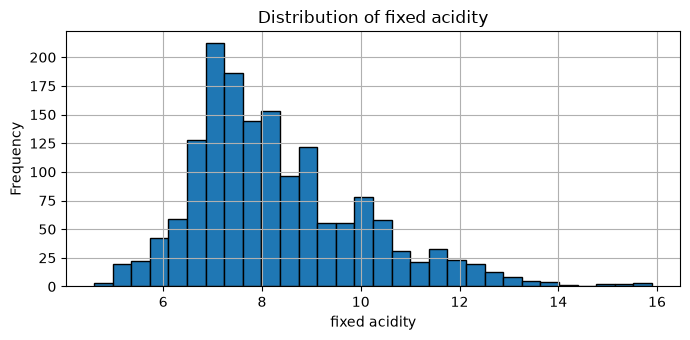

Outlier cnt of fixed acidity: 49
volatile acidity


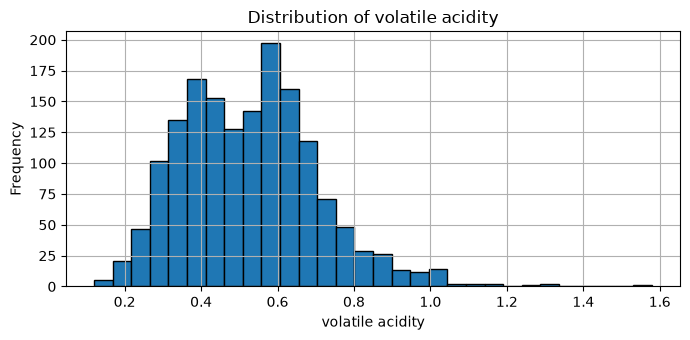

Outlier cnt of volatile acidity: 19
citric acid


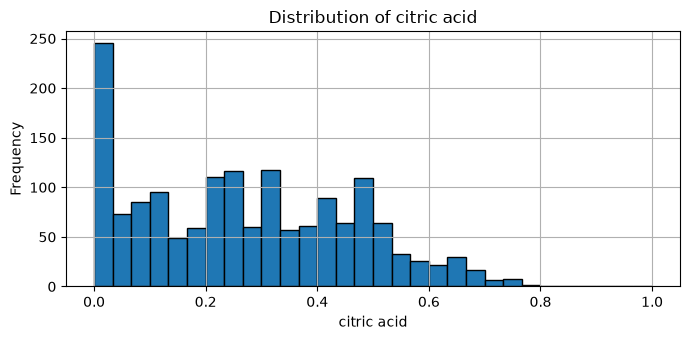

Outlier cnt of citric acid: 1
residual sugar


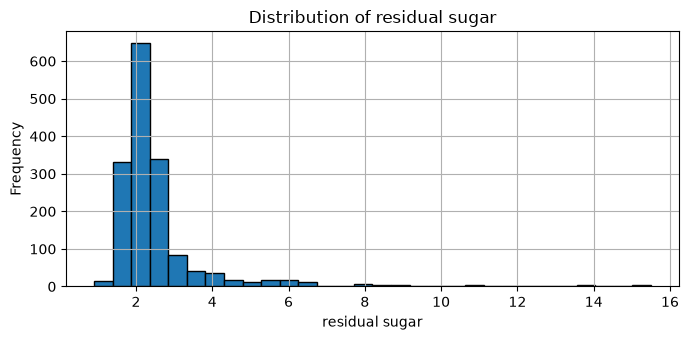

Outlier cnt of residual sugar: 155
chlorides


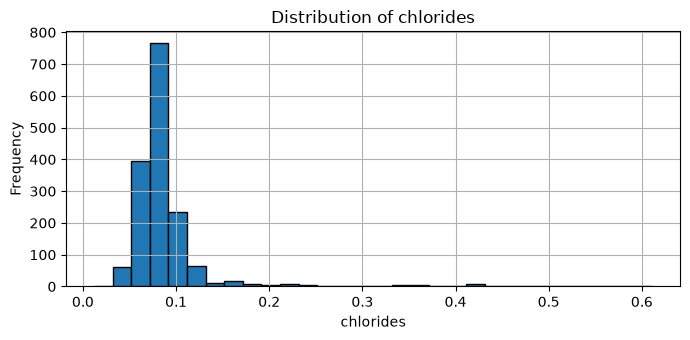

Outlier cnt of chlorides: 112
free sulfur dioxide


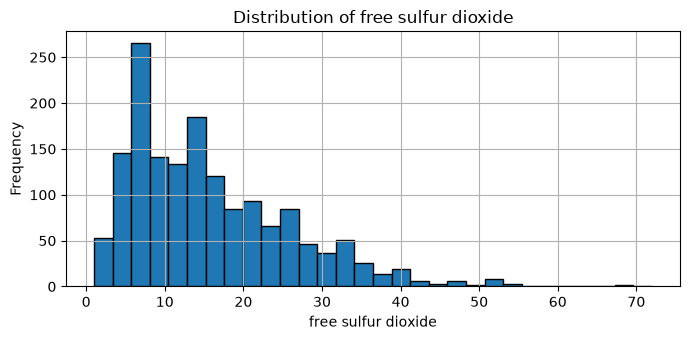

Outlier cnt of free sulfur dioxide: 30
total sulfur dioxide


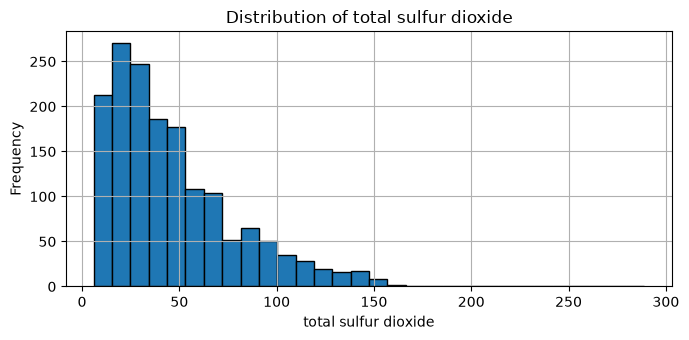

Outlier cnt of total sulfur dioxide: 55
density


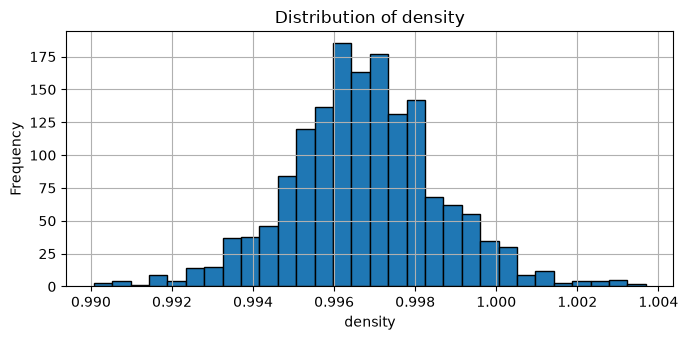

Outlier cnt of density: 45
pH


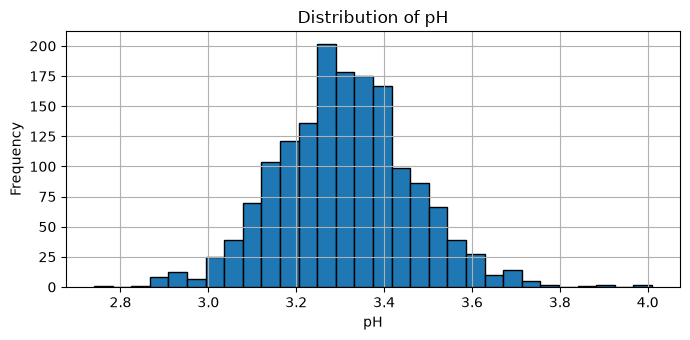

Outlier cnt of pH: 35
sulphates


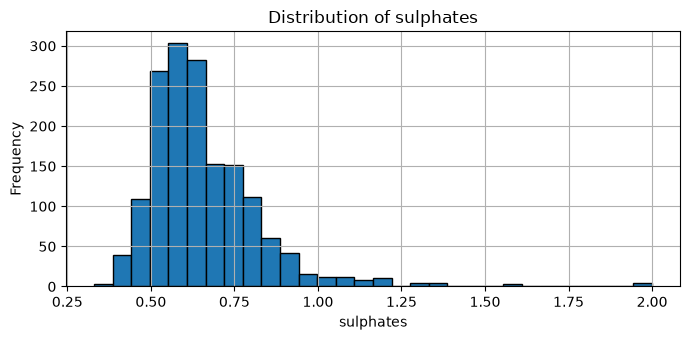

Outlier cnt of sulphates: 59
alcohol


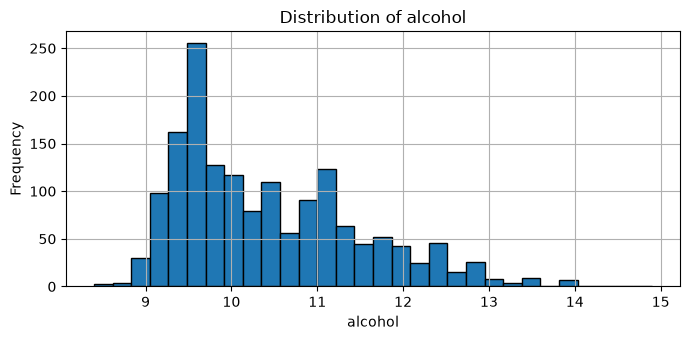

Outlier cnt of alcohol: 13
quality


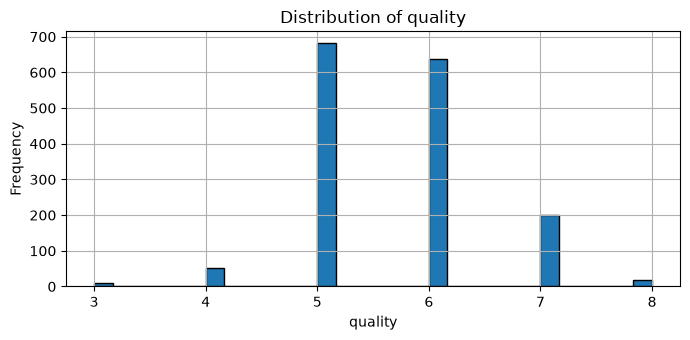

Outlier cnt of quality: 28


volatile acidity       -0.390558
total sulfur dioxide   -0.185100
density                -0.174919
chlorides              -0.128907
pH                     -0.057731
free sulfur dioxide    -0.050656
residual sugar          0.013732
fixed acidity           0.124052
citric acid             0.226373
sulphates               0.251397
alcohol                 0.476166
quality                 1.000000
Name: quality, dtype: float64

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def describe_coloumn(df: pd.DataFrame, column: str):
    print(column)
    _, ax = plt.subplots(figsize=(7, 3.5))
    df[column].hist(ax=ax, bins=30, edgecolor='black')
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")
    plt.tight_layout()
    plt.show()
    df[column].describe()

    Q1, Q3 = df[column].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    outliers = df[(df[column] < Q1 - IQR * 1.5) | (df[column] > Q3 + IQR * 1.5)]
    print(f"Outlier cnt of {column}: {len(outliers)}")


url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=';')

print(f"Shape: {df.shape}")
print(f"Coloumns: {df.columns.to_list()}")
print("Quality column description:")
display(df["quality"].describe())
print("Head of dataset:")
display(df.head())
print("Duplicated rows cnt:")
display(int(df.duplicated().sum()))
print("Null rows cnt:")
display(df.isnull().sum())

for col in df.columns:
    describe_coloumn(df, col)

display(
    df.corr()['quality'].sort_values()
    )


DataFrame состоит из 1599 строк с 12 столбцами. Они перечислены в выводе скрипта.

Дубликатов -- 240 строк. Это примерно $15$% от всего датасета. Для обучения стоит исключить дубликаты.

"В среднем" (обычно) качество вина - число от 5 до 6. Только доли получают остальные оценки.

Как видно из таблицы корреляций качества и остальных признаков: нет ни одной сильной корреляции ($|r| > 0.7$). 
Средняя корреляция выявлена у параметров: "volatile acidity", "alcohol" - отрицательная и положительная соответсвенно. То есть, чем больше нестабильной кислотности, тем оценка ниже и чем выше содержание этанола - тем выше. Остальные параметры имеют с качеством низкую корреляцию.

Как видно из корреляций почти нулевую имеют: "pH", "free sulfiric dioxide", "residual sugar". Значит, линейной зависимости между этими параметрами почти нет.

# Fix skew

In [32]:
from sklearn.base import BaseEstimator, TransformerMixin

class SkewFixer(BaseEstimator, TransformerMixin):
    def __init__(self, threshold: float=1.0):
        self.threshold = threshold 

    def fit(self, X: pd.DataFrame, y: pd.Series | None=None):
        skews = X.skew()
        self.coloumns_ = skews[skews.abs() > self.threshold].index.to_list()
        return self

    def transform(self, X: pd.DataFrame):
        new_x = X.copy()
        for col in self.coloumns_:
            new_x[col] = np.log1p(X[col])
        return new_x

    def get_feature_names_out(self, input_features=None):
        return np.array(input_features)



# Poly some features

In [33]:
from itertools import combinations_with_replacement

from sklearn.base import BaseEstimator, TransformerMixin

class PolySomeColmuns(BaseEstimator, TransformerMixin):
    def __init__(self, columns: list[str]):
        self.columns = columns

    def fit(self, X: pd.DataFrame, y:pd.Series | None=None):
        self.columns_: list[str] = []
        x_index = X.columns.to_list()
        for col in self.columns:
            if col in x_index:
                self.columns_.append(col)
        return self

    def transform(self, X: pd.DataFrame):
        new_x = X.copy()
        for fst, snd in combinations_with_replacement(self.columns_, 2):
            if fst != snd:
                new_x[f'{fst} * {snd}'] = new_x[fst] * new_x[snd] 
            else:
                new_x[f'{fst}^2'] = new_x[fst] ** 2
        return new_x

    def get_feature_names_out(self, input_features=None):
        base = list(input_features) if input_features is not None else []
        extras = [
            f'{fst}^2' if fst == snd else f'{fst} * {snd}'
            for fst, snd in combinations_with_replacement(self.columns_, 2)
        ]
        return np.array(base + extras)

Разделим выборку на train и test.

In [34]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TEST_SIZE = 0.2

df = df.drop_duplicates()

X = df.drop(columns=['quality'])
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)


(1087, 11) (272, 11)


Разбили недубликатные строки 80-20. Размеры показаны выше.

Такой способ был выбран, для того, чтобы оставить достаточное количество данных для train и имень достаточное количество данных на test. Если бы у нас было гораздо больше данных - можно было бы взять 90-10.

Если оценивать модель на одной и той же тестовой выборке - мы просто "подгонем" её под эту выборку, и, если тестовая выборка не покрывает нужного количества возможных данных, то на непроверенных данных у нас может сильно вырасти ошибка.

# Baseline

In [35]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

models = {}

def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

def mae(y_true, y_pred):
    return mean_absolute_error(y_true, y_pred)

baseline = Pipeline([
    ('log', SkewFixer()),
    ('poly', PolySomeColmuns([
        'alcohol', 
        'volatile acidity', 
        'sulphates', 
        ])),
    ("scaler", StandardScaler()),
    ("model", DummyRegressor(strategy='mean')),
])

baseline.fit(X_train, y_train)

pred_base = baseline.predict(X_test)
print("Baseline RMSE: ", rmse(y_test, pred_base))
print("Baseline MAE: ", mae(y_test, pred_base))
models["Baseline"] = baseline

Baseline RMSE:  0.8442825185874644
Baseline MAE:  0.7048778342983928


# Linear

In [36]:
from sklearn.linear_model import LinearRegression

linreg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linreg_modified = Pipeline([
    ('log', SkewFixer()),
    ('poly', PolySomeColmuns([
        'alcohol', 
        'volatile acidity', 
        'sulphates', 
        ])),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linreg.fit(X_train, y_train)
linreg_modified.fit(X_train, y_train)

pred_train = linreg.predict(X_train)
pred_test = linreg.predict(X_test)

pred_train_modified = linreg_modified.predict(X_train)
pred_test_modified = linreg_modified.predict(X_test)

print("Linear")
print("Train RMSE: ", rmse(y_train, pred_train))
print("Test RMSE: ", rmse(y_test, pred_test))
print("Test MAE: ", mae(y_test, pred_test))

coefs = pd.Series(linreg.named_steps["model"].coef_, index=linreg[:-1].get_feature_names_out(X_train.columns)).sort_values()
display(coefs)

print("Linear modified")
print("Train RMSE: ", rmse(y_train, pred_train_modified))
print("Test RMSE: ", rmse(y_test, pred_test_modified))
print("Test MAE: ", mae(y_test, pred_test_modified))

coefs = pd.Series(linreg_modified.named_steps["model"].coef_, index=linreg_modified[:-1].get_feature_names_out(X_train.columns)).sort_values()
display(coefs)

models["Linear"] = linreg
models["LinearModified"] = linreg_modified


Linear
Train RMSE:  0.6585388890409953
Test RMSE:  0.656512760797608
Test MAE:  0.5041409053480713


volatile acidity       -0.178494
total sulfur dioxide   -0.123600
pH                     -0.121548
chlorides              -0.115971
fixed acidity          -0.049675
citric acid            -0.019148
residual sugar         -0.005231
density                 0.042064
free sulfur dioxide     0.048723
sulphates               0.148499
alcohol                 0.333970
dtype: float64

Linear modified
Train RMSE:  0.6435057224822893
Test RMSE:  0.6358466293103775
Test MAE:  0.4894477117552358


alcohol^2                      -0.715718
sulphates^2                    -0.657461
volatile acidity               -0.164123
pH                             -0.140754
total sulfur dioxide           -0.111419
volatile acidity^2             -0.069901
chlorides                      -0.062942
volatile acidity * sulphates   -0.055328
citric acid                    -0.035837
fixed acidity                  -0.027661
density                        -0.023369
residual sugar                  0.004986
free sulfur dioxide             0.060041
alcohol * volatile acidity      0.129767
sulphates                       0.223397
alcohol                         0.621463
alcohol * sulphates             0.739294
dtype: float64

Проведём регуляризацию

In [37]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge, Lasso

ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=0.01, max_iter=10000))
])
ridge_modified = Pipeline([
    ('log', SkewFixer()),
    ('poly', PolySomeColmuns([
        'alcohol', 
        'volatile acidity', 
        'sulphates', 
        ])),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

lasso_modified = Pipeline([
    ('log', SkewFixer()),
    ('poly', PolySomeColmuns([
        'alcohol', 
        'volatile acidity', 
        'sulphates', 
        ])),
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=0.01, max_iter=10000))
])

for name, model in {"Ridge": ridge, "Lasso": lasso, "RidgeModified": ridge_modified, "LassoModified": lasso_modified}.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name, 'RMSE = ', rmse(y_test, pred))
    print(name, 'MAE = ', mae(y_test, pred))
    coefs = pd.Series(model.named_steps['model'].coef_, index=model[:-1].get_feature_names_out(X_train.columns)).sort_values()
    display(coefs)
    models[name] = model

Ridge RMSE =  0.6563769846217308
Ridge MAE =  0.5040909797091884


volatile acidity       -0.178297
total sulfur dioxide   -0.123306
pH                     -0.120306
chlorides              -0.115706
fixed acidity          -0.047756
citric acid            -0.018957
residual sugar         -0.004703
density                 0.040202
free sulfur dioxide     0.048473
sulphates               0.148547
alcohol                 0.332665
dtype: float64

Lasso RMSE =  0.6521999134022233
Lasso MAE =  0.5012316779346321


volatile acidity       -0.170396
chlorides              -0.095767
total sulfur dioxide   -0.090137
pH                     -0.070876
residual sugar          0.000000
citric acid            -0.000000
density                -0.000000
fixed acidity           0.000000
free sulfur dioxide     0.018573
sulphates               0.136755
alcohol                 0.305073
dtype: float64

RidgeModified RMSE =  0.6346173799393344
RidgeModified MAE =  0.48949511449791966


sulphates^2                    -0.634643
alcohol^2                      -0.462728
volatile acidity               -0.158704
pH                             -0.137914
total sulfur dioxide           -0.115792
volatile acidity^2             -0.069760
chlorides                      -0.066876
volatile acidity * sulphates   -0.059248
citric acid                    -0.035661
fixed acidity                  -0.024375
density                        -0.021740
residual sugar                  0.004591
free sulfur dioxide             0.063189
alcohol * volatile acidity      0.127694
sulphates                       0.258491
alcohol                         0.400050
alcohol * sulphates             0.673676
dtype: float64

LassoModified RMSE =  0.6361963173445983
LassoModified MAE =  0.4914178063851721


sulphates^2                    -0.177637
total sulfur dioxide           -0.088283
volatile acidity               -0.084604
chlorides                      -0.084006
pH                             -0.072669
volatile acidity^2             -0.070961
density                        -0.005822
volatile acidity * sulphates   -0.001001
alcohol * volatile acidity     -0.000000
fixed acidity                   0.000000
citric acid                    -0.000000
sulphates                       0.000000
alcohol^2                       0.000000
residual sugar                 -0.000000
free sulfur dioxide             0.032739
alcohol                         0.106702
alcohol * sulphates             0.402067
dtype: float64

Для того, чтобы понизить RMSE было предпринято много разных попыток: добавление новых фич, зависящих от старых (там, увы, получалась большая корреляция), логарифмизация "скошенных" данных, добавление квардратичных и кубичиских многочленов. По отдельности, влияние было довольно слабым или даже отрицательным, но объеденив логарифмизацию и возведение в степень, получился прирост примерно в 0.01-0.02 на данном train/test split'е. На модифицированном датасете наблюдается, что именно произведения влияют больше всего, возможно, это связано как-то с их химией.

Среди чисто линейных самые важные признаки: содержание алкоголя, содержание летучих кислот, содержание сульфаты. Среди модифицированных - произведение алкоголя на сульфаты, квадрат сульфатов, алкоголь.

# Нелинейные модели

## Случайный лес

In [38]:
from sklearn.ensemble import RandomForestRegressor

random_forest = Pipeline([
    ('model', RandomForestRegressor(
        n_estimators=500,
        max_depth=None,
        min_samples_leaf=1,
        min_samples_split=2,
        max_features=1.0,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

random_forest_limited = Pipeline([
    ('model', RandomForestRegressor(
        n_estimators=500,
        max_depth=15,
        min_samples_leaf=8,
        oob_score = True,
        min_samples_split=10,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest.fit(X_train, y_train)
random_forest_limited.fit(X_train, y_train)

train_prediction = random_forest.predict(X_train)
test_prediction = random_forest.predict(X_test)
print("Random Forest Regressor")
print("Train RMSE = ", rmse(y_train, train_prediction))
print("Train MAE = ", mae(y_train, train_prediction))
print("Test RMSE = ", rmse(y_test, test_prediction))
print("Test MAE = ", mae(y_test, test_prediction))

train_prediction_limited = random_forest_limited.predict(X_train)
test_prediction_limited = random_forest_limited.predict(X_test)
print("Limited Random Forest Regressor")
print("Train RMSE = ", rmse(y_train, train_prediction_limited))
print("Train MAE = ", mae(y_train, train_prediction_limited))
print("Test RMSE = ", rmse(y_test, test_prediction_limited))
print("Test MAE = ", mae(y_test, test_prediction_limited))
models["Forest"] = random_forest
models["LimitedForest"] = random_forest_limited

Random Forest Regressor
Train RMSE =  0.24023630654145675
Train MAE =  0.1839760809567617
Test RMSE =  0.6197974408200302
Test MAE =  0.4679338235294117
Limited Random Forest Regressor
Train RMSE =  0.4944461678738513
Train MAE =  0.3760491501804795
Test RMSE =  0.6148152938190156
Test MAE =  0.4650582346103883


По сравнению с линейными на test падение составляет примерно 0.01-0.02 на данном split. Посмотрим на feature importance.

In [39]:
imp = pd.Series(
    random_forest.named_steps['model'].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(imp.round(4))


alcohol                 0.2800
sulphates               0.1319
volatile acidity        0.1147
total sulfur dioxide    0.0797
chlorides               0.0661
residual sugar          0.0611
pH                      0.0605
density                 0.0549
fixed acidity           0.0533
free sulfur dioxide     0.0506
citric acid             0.0472
dtype: float64

Так как в лесе нет дополнительных фичей, будем сравнивать с обычной линейной. В топ 3 по влиянию все те же фичи, но сульфаты и летучие кислоты поменялись местами.

## Градиентный бустинг

In [40]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting = Pipeline([
    ('model', GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        min_samples_leaf=5,
        subsample=0.8,
        max_depth=2,
        random_state = RANDOM_STATE
        )
    )
])

gradient_boosting.fit(X_train, y_train)

train_prediction= gradient_boosting.predict(X_train)
test_prediction= gradient_boosting.predict(X_test)

print("Gradient boosting")
print("Train RMSE = ", rmse(y_train, train_prediction))
print("Train MAE = ", mae(y_train, train_prediction))
print("Test RMSE = ", rmse(y_test, test_prediction))
print("Test MAE = ", mae(y_test, test_prediction))

models['Gradient Boosting'] = gradient_boosting

Gradient boosting
Train RMSE =  0.5418566304618568
Train MAE =  0.4236233336182437
Test RMSE =  0.6207422157042335
Test MAE =  0.4826445114980822


In [41]:
imp = pd.Series(
    gradient_boosting.named_steps['model'].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(imp.round(4))

alcohol                 0.3603
volatile acidity        0.1561
sulphates               0.1474
total sulfur dioxide    0.0645
pH                      0.0513
chlorides               0.0461
density                 0.0424
fixed acidity           0.0401
residual sugar          0.0349
citric acid             0.0306
free sulfur dioxide     0.0263
dtype: float64

Топ 3 признака совпадают с линейными алгоритмами.

# Тесты всех моделей

In [42]:
from typing import Any

def test_model(model: Pipeline):
    prediction = model.predict(X_test)

    return rmse(y_test, prediction), mae(y_test, prediction) 

rows: list[dict[str, Any]] = []
for name, model in models.items(): # type: ignore
    rmse_value, mae_value = test_model(model) # type: ignore
    rows.append({ # type: ignore
        'model': name,
        'rmse': rmse_value,
        'mae': mae_value,
    })

result = pd.DataFrame(rows).set_index('model')
result = result.sort_values('rmse', ascending=True)
display(result)



,rmse,mae
model,,
LimitedForest,0.614815,0.465058
Forest,0.619797,0.467934
Gradient Boosting,0.620742,0.482645
RidgeModified,0.634617,0.489495
LinearModified,0.635847,0.489448
LassoModified,0.636196,0.491418
Lasso,0.652200,0.501232
Ridge,0.656377,0.504091
Linear,0.656513,0.504141


В результате все модели оказались лучше Baseline и уложились в RMSE < 0.7 на данном split. Самым лучшим алгоритмом оказался random forest regressor, но у него малый отрыв от градиента. Это объясняется тем, что у GB более сложная регуляризация (больше гиперпараметров) и у нас малое количество данных. Так же, обратим внимание на линейные модели - хоть они и проиграли, но всё равно показывают интересную "динамику" в своей группе. Благодаря feature enginring и логарифмизации некоторых параметров получилось сбить примерно 0.015 RMSE по сравнению с обычными.

# Feature importance

Как было сказано ранее, в топ 3 вошли: содержание алкоголя, летучие кислоты и сульфаты. Единственное отличие между линейными и лесом - это места летучих кислот и сульфатов. При анализе был выделен алкоголь и летучие кислоты, но не были выделены сульфаты, так как их линейная связь меньше остальных ($r < 0.3$, что показывает линейную зависимость). Как раз по 4-ому графику видно, что зависимость больше квадратичная, чем линейная.

Feature importance только показывает корреляцию между фичами и оценкой. Допустим, явно не будет верно сказать, что если в вине по линейной модели будет, 50% алкоголя, то оно будет 12 из 10. 

forest


alcohol                 0.386373
sulphates               0.160943
volatile acidity        0.117808
total sulfur dioxide    0.071907
chlorides               0.048444
pH                      0.044035
free sulfur dioxide     0.037965
citric acid             0.036265
density                 0.035320
fixed acidity           0.032189
residual sugar          0.028751
dtype: float64

gb


alcohol                 0.360272
volatile acidity        0.156128
sulphates               0.147412
total sulfur dioxide    0.064506
pH                      0.051334
chlorides               0.046085
density                 0.042381
fixed acidity           0.040087
residual sugar          0.034897
citric acid             0.030589
free sulfur dioxide     0.026308
dtype: float64

ridge


alcohol                 0.332665
volatile acidity        0.178297
sulphates               0.148547
total sulfur dioxide    0.123306
pH                      0.120306
chlorides               0.115706
free sulfur dioxide     0.048473
fixed acidity           0.047756
density                 0.040202
citric acid             0.018957
residual sugar          0.004703
dtype: float64

ridge mod


alcohol * sulphates             0.673676
sulphates^2                     0.634643
alcohol^2                       0.462728
alcohol                         0.400050
sulphates                       0.258491
volatile acidity                0.158704
pH                              0.137914
alcohol * volatile acidity      0.127694
total sulfur dioxide            0.115792
volatile acidity^2              0.069760
chlorides                       0.066876
free sulfur dioxide             0.063189
volatile acidity * sulphates    0.059248
citric acid                     0.035661
fixed acidity                   0.024375
density                         0.021740
residual sugar                  0.004591
dtype: float64

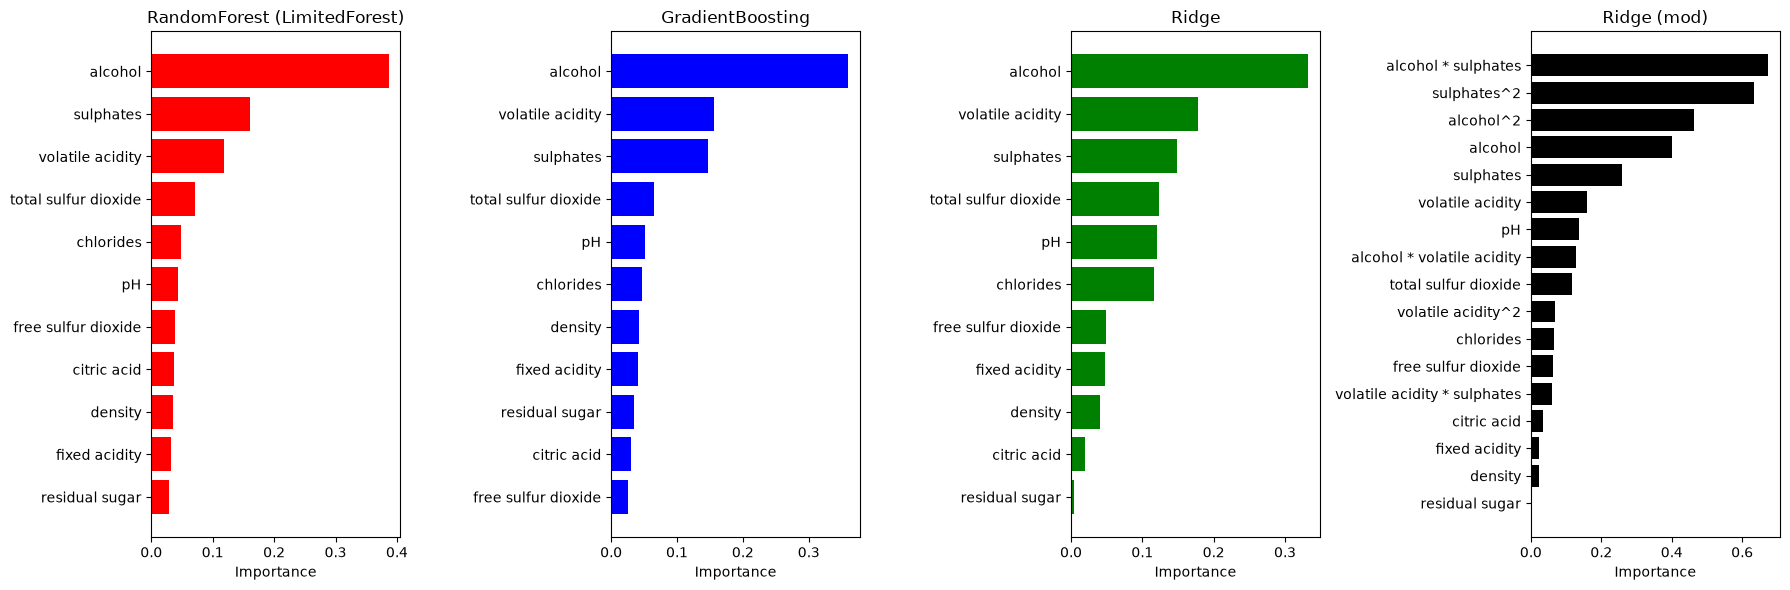

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

imp_rf = pd.Series(
    models['LimitedForest'].named_steps['model'].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

imp_gb = pd.Series(
    models['Gradient Boosting'].named_steps['model'].feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

imp_linear = pd.Series(
    np.abs(models['Ridge'].named_steps['model'].coef_),
    index=X_train.columns
).sort_values(ascending=False)


imp_linear_mod = pd.Series(
    np.abs(models['RidgeModified'].named_steps['model'].coef_),
    index=models['RidgeModified'][:-1].get_feature_names_out(X_train.columns)
).sort_values(ascending=False)

print('forest')
display(imp_rf)
print('gb')
display(imp_gb)
print('ridge')
display(imp_linear)
print('ridge mod')
display(imp_linear_mod)

fig, axes = plt.subplots(1, 4, figsize=(18, 6))

for ax, imp, title, color in [
    (axes[0], imp_rf,     'RandomForest (LimitedForest)', 'red'),
    (axes[1], imp_gb,     'GradientBoosting',             'blue'),
    (axes[2], imp_linear, 'Ridge',             'green'),
    (axes[3], imp_linear_mod, 'Ridge (mod)',             'black'),
]:
    imp_sorted = imp.sort_values()
    ax.barh(imp_sorted.index, imp_sorted.values, color=color)
    ax.set_title(title)
    ax.set_xlabel('Importance')

plt.tight_layout()
plt.show()

# Анализ ошибок

Test RMSE: 0.6148
Test MAE:  0.4651
Max |error|: 2.0542
Median |error|: 0.3601


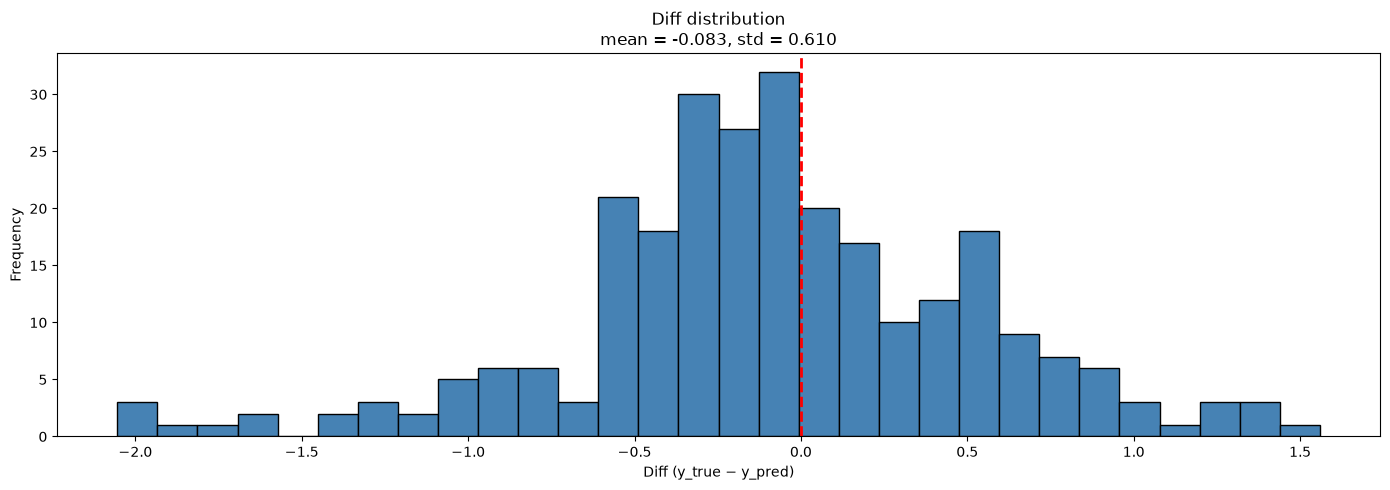

Mean diff:   -0.0828
Std diff:    0.6103


,y_true,y_pred,diff,abs_error
1469,3,5.054234,-2.054234,2.054234
1478,3,4.996367,-1.996367,1.996367
690,3,4.961010,-1.961010,1.961010
899,3,4.860874,-1.860874,1.860874
1423,4,5.807626,-1.807626,1.807626


,y_true,y_pred,diff,abs_error
1503,6,5.998455,0.001545,0.001545
1012,5,4.995223,0.004777,0.004777
304,5,4.993962,0.006038,0.006038
1376,5,4.991327,0.008673,0.008673
55,5,5.010427,-0.010427,0.010427


In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

best_model = models['LimitedForest']
pred_test = best_model.predict(X_test)
diff = y_test - pred_test

error_df = pd.DataFrame({
    'y_true':    y_test.values,
    'y_pred':    pred_test,
    'diff':  diff.values,
    'abs_error': np.abs(diff.values),
}, index=y_test.index)

print(f"Test RMSE: {rmse(y_test, pred_test):.4f}")
print(f"Test MAE:  {mae(y_test, pred_test):.4f}")
print(f"Max |error|: {error_df['abs_error'].max():.4f}")
print(f"Median |error|: {error_df['abs_error'].median():.4f}")

fig, axe = plt.subplots(figsize=(14, 5))

axe.hist(diff, bins=30, edgecolor='black', color='steelblue')
axe.axvline(0, color='red', linestyle='--', linewidth=2)
axe.set_xlabel('Diff (y_true − y_pred)')
axe.set_ylabel('Frequency')
axe.set_title(f'Diff distribution\nmean = {diff.mean():.3f}, std = {diff.std():.3f}')

plt.tight_layout()
plt.show()

print(f"Mean diff:   {diff.mean():+.4f}")
print(f"Std diff:    {diff.std():.4f}")

top_errors = error_df.sort_values('abs_error', ascending=False).head(5)
bottom_errors = error_df.sort_values('abs_error', ascending=True).head(5)
display(top_errors)
display(bottom_errors)

Как видно из топ 5 с самыми большими ошибками - это те, у которых оценка низкая. В данных не было достаточного количества вин с низкой оценкой, поэтому модель завысила результирующую оценку. А если посмотрим на противоположное - тут как раз в районе 5-6, так как большинство оценок - это 5 или 6.